In [35]:
# @title Run to load helper functions
from dataclasses import dataclass
import networkx as nx
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np
from scipy.optimize import linprog
import graphviz
pio.templates.default = "plotly_white"

def plot_graph(g):
    plot = graphviz.Digraph(engine="circo")
    for v in g.nodes:
        plot.node(v)
    for u, v in g.edges():
        label = str(g.edges[(u, v)]['capacity']) if "capacity" in g.edges[(u, v)] else ""
        plot.edge(u, v, label=label)
    display(plot)

def plot_bipartite(g, left, weights=False, matching=None):
    fig = go.Figure()
    right = [i for i in g.nodes if i not in left]
    fig.add_trace(
        go.Scatter(
            x=[0]*len(left),
            y=list(range(len(left))),
            text = list(map(str, left)),
            textposition="middle left",
            mode='markers+text',
            marker=dict(color="red")
        )
    )
    fig.add_trace(
        go.Scatter(
            x=[1]*len(right),
            y=list(range(len(right))),
            text = list(map(str, right)),
            textposition="middle right",
            mode='markers+text',
            marker=dict(color="blue")
        )
    )
    for u,v,d in g.edges(data=True):
        width = (1/3 + d['weight'])*3/4 if weights else 1
        text = "Weight: " + str(d['weight']) if weights else ""
        color = "black"
        if matching is not None and (u, v) in matching:
            color="pink"
        fig.add_trace(
            go.Scatter(
                name=f"{u}, {v}",
                x= np.linspace(0,1,101),
                y=np.linspace(left.index(u), right.index(v), 101),
                mode='lines',
                marker=dict(color=color),
                line=dict(width=width),
                text= text
            )
        )
    fig.update_layout(showlegend=False, width=700 , height=1000)
    fig.update_xaxes(visible=False, range=(-0.1, 1.1))
    fig.update_yaxes(visible=False)
    return fig

WORK_TIMES = [
    "Monday AM"
     , "Tuesday AM"
     , "Wednesday AM"
     , "Thursday AM"
     , "Friday_AM"
     , "Saturday_AM"
     , "Sunday_AM"
     , "Monday_PM"
     , "Tuesday_PM"
     , "Wednesday_PM"
     , "Thursday_PM"
     , "Friday_PM"
     , "Saturday_PM"
     , "Sunday_PM"
]


@dataclass
class Response:
    student_id: str
    availability: set

def get_random_responses(n, seed):
    seed_n = int.from_bytes(seed.encode('utf-8'), "little")
    rng = np.random.default_rng(seed=seed_n)
    cs_students = []
    business_students = []
    c = 0
    p = [0.1, 0.3, 0.4, 0.2]
    for _ in range(n//2):
        num_days_available = rng.choice([1, 2, 3, 4], p=p)
        times = set(rng.choice(WORK_TIMES, size=num_days_available, replace=False))
        cs_students.append(Response(str(c), times))
        c+=1
    for _ in range(n//2):
        num_days_available = rng.choice([1, 2, 3, 4], p=p)
        times = set(rng.choice(WORK_TIMES, size=num_days_available, replace=False))
        business_students.append(Response(str(c), times))
        c+=1
    return cs_students, business_students

# Basics: Graphs, Flow, and LP in Python

Before we get started with the exercises, let's get acquainted with graphs and LPs in Python, as well as some of the helper functions I've provided for you.

## Directed graphs + Flow

Here's how to define a directed graph using the networkx library (imported as nx), this is an example from the flow lecture.


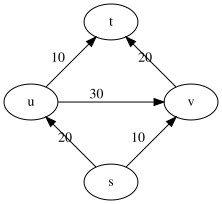

In [36]:
g = nx.DiGraph()
g.add_node("s")
g.add_node("u")
g.add_node("v")
g.add_node("t")
g.add_edge("s", "u", capacity=20)
g.add_edge("s", "v", capacity=10)
g.add_edge("u", "v", capacity=30)
g.add_edge("u", "t", capacity=10)
g.add_edge("v", "t", capacity=20)
plot_graph(g)

You can solve the network flow problem on the graph by calling `nx.maximum_flow`, you'll receive the flow value as well as some data structure from which you can extract the flow values along each edge!

In [37]:
flow_value, flow_dict = nx.maximum_flow(g, "s", "t")
print(flow_value)
print(flow_dict)

30
{'s': {'u': 20, 'v': 10}, 'u': {'v': 10, 't': 10}, 'v': {'t': 20}, 't': {}}


## Plotting bipartite graphs

When your graph is bipartite, the `plot_graph` function doesn't always plot it in a way that "looks bipartite".

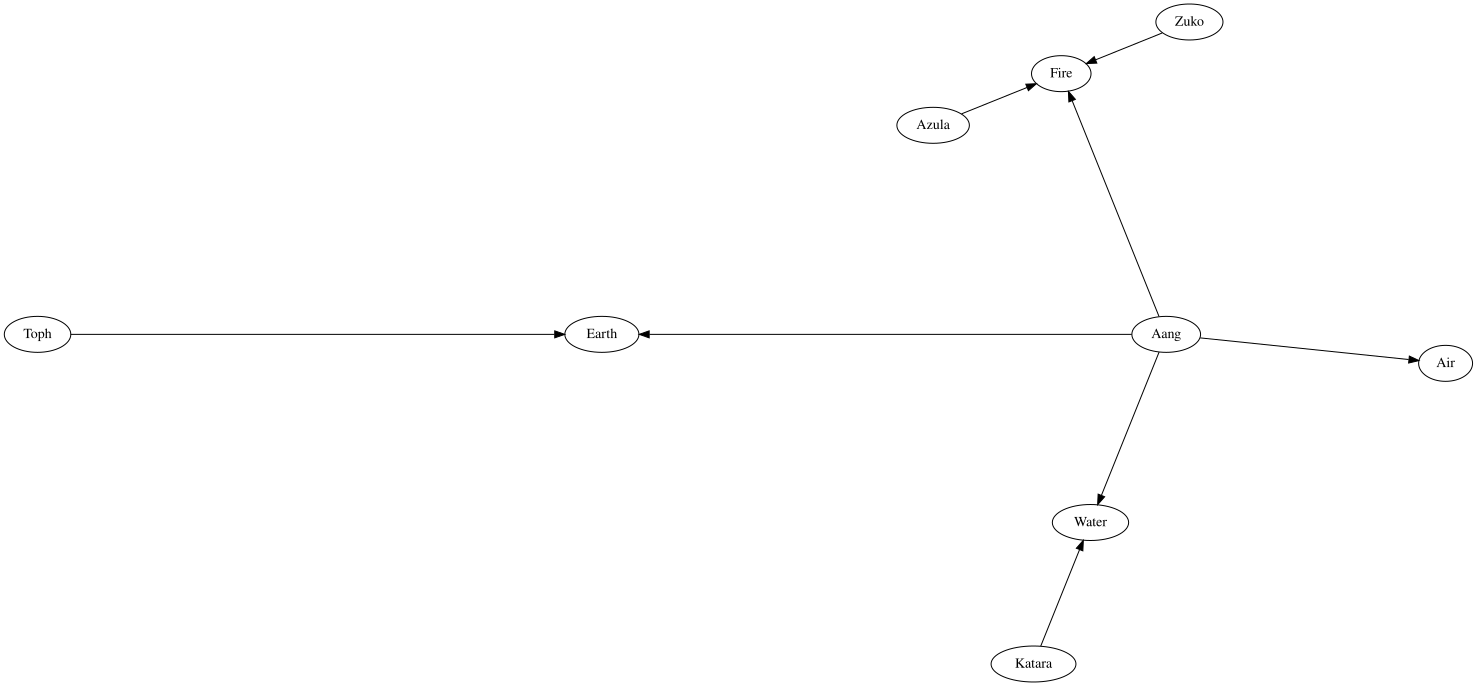

In [38]:
g = nx.DiGraph()
g.add_node("Earth")
g.add_node("Water")
g.add_node("Air")
g.add_node("Fire")
g.add_node("Aang")
g.add_node("Katara")
g.add_node("Toph")
g.add_node("Zuko")
g.add_node("Azula")
g.add_edge("Aang", "Earth", weight=1)
g.add_edge("Aang", "Air", weight=2)
g.add_edge("Aang", "Water", weight=1)
g.add_edge("Aang", "Fire", weight=1)
g.add_edge("Katara", "Water", weight=2)
g.add_edge("Toph", "Earth", weight=3)
g.add_edge("Zuko", "Fire", weight=1)
g.add_edge("Azula", "Fire", weight=2)
plot_graph(g)

Instead, you can use the `plot_bipartite(g, left, weights=False, matching=None)` function. Here, `g` is a graph, and `left` is a list of vertices to be plotted on the left.

Here are several examples showcasing the different parameters.

In [39]:
plot_bipartite(g, ["Aang", "Katara", "Toph", "Zuko", "Azula"])

In [40]:
plot_bipartite(g, ["Aang", "Katara", "Toph", "Zuko", "Azula"], weights=True)

A matching is represented as a list of edges

In [41]:
matching = [("Aang", "Air"), ("Katara", "Water"), ("Zuko", "Fire"), ("Toph", "Earth") ]
plot_bipartite(g, ["Aang", "Katara", "Toph", "Zuko", "Azula"], weights=True, matching=matching)

## Linear Programs

For linear programs, we'll use the popular scientific computing library scipy. The documentation can be found [here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html)

Here's an example from the lecture...

Note that `linprog` minimizes by default so you need to negate your objective function if you want to maximize.

In [42]:
c = [-3,-1,-2]
A = [
        [1, 1, 3],
        [2, 2, 5],
        [4, 1, 2]
    ]
b = [30, 24, 36]
linprog(c, A_ub=A, b_ub=b, bounds=(0,None))

        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -28.0
              x: [ 8.000e+00  4.000e+00  0.000e+00]
            nit: 2
          lower:  residual: [ 8.000e+00  4.000e+00  0.000e+00]
                 marginals: [ 0.000e+00  0.000e+00  1.667e-01]
          upper:  residual: [       inf        inf        inf]
                 marginals: [ 0.000e+00  0.000e+00  0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 1.800e+01  0.000e+00  0.000e+00]
                 marginals: [-0.000e+00 -1.667e-01 -6.667e-01]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

# Match Making

Imagine you are in the following scenario. You are a TA for an interdisciplinary course hosted by the CS and Business departments. As a part of the course, students need to pair up - one from the CS department and one from the Business department to develop an app.

Since the CS students and Business students don't take that many other classes together, many of them would like some help finding a project partner. To facilitate this, the professor sent out a form asking for the student's home department and availability to work on a project. To simplify the problem a bit, let's suppose that every student is the class is either in the CS department or the Business department but not both. The prof, who hears that you have taken 373, tasks you with matching the students.

Here is the data from the form responses.

In [43]:
cs_students, business_students = get_random_responses(30, seed="dengyuny,meneze94,hassa722")

In [44]:
cs_students[0]

Response(student_id='0', availability={'Wednesday AM', 'Friday_AM'})

In [45]:
cs_students[0].student_id

'0'

In [46]:
cs_students[0].availability

{'Friday_AM', 'Wednesday AM'}

As you can see, a response contains a student ID and a set of timeslots in which they are available.

A CS student (one from the `cs_students` list) and a Business student can be paired up iff they overlap in their avaialability.

## Task 1
Model this problem as a network flow problem. Solve the flow problem and extract a matching of the students. To submit, change the seed to a string containing your UTorIDs, run your code, and upload.
1. The block of code that generated the responses (above)
2. A screenshot of the flow dictionary you obtained
3. A screenshot of the graph you obtained along with the matching. I.e., it should be the output of `plot_bipartite` with the matching parameter equal to the matching you found.

In [58]:
# Setting up graph
t1_graph = nx.DiGraph()

t1_graph.add_node("s")
t1_graph.add_node("t")

business_student_ids = []

for business_student in business_students:
    t1_graph.add_node(business_student.student_id)
    business_student_ids.append(business_student.student_id)
    t1_graph.add_edge("s", business_student.student_id, weight=1)

for cs_student in cs_students:
    t1_graph.add_node(cs_student.student_id)
    t1_graph.add_edge(cs_student.student_id, "t", weight=1)
    for business_student in business_students:
        if len(business_student.availability & cs_student.availability) > 0:
            t1_graph.add_edge(business_student.student_id, cs_student.student_id, weight=1)

# Solving max-flow
t1_flow_value, t1_flow_dict = nx.maximum_flow(t1_graph, "s", "t", capacity = "weight")
print(t1_flow_dict)

# Building matchings
print(f"Students Matched: {t1_flow_value}")
t1_matching = []
for business_student_id in business_student_ids:
    flow_dict = t1_flow_dict[business_student_id]
    for cs_student_id, flow_value in flow_dict.items():
        if flow_value > 0:
            t1_matching.append((business_student_id, cs_student_id))
print(f"Student ID Matches:\n\t{"\n\t".join([str(pairing) for pairing in t1_matching])}")

# Graphing results
t1_graph.remove_node("s")
t1_graph.remove_node("t")
plot_bipartite(t1_graph, left=business_student_ids, matching=t1_matching)

{'s': {'15': 1, '16': 1, '17': 1, '18': 1, '19': 1, '20': 1, '21': 1, '22': 1, '23': 1, '24': 1, '25': 1, '26': 1, '27': 1, '28': 1, '29': 1}, 't': {}, '15': {'0': 0, '2': 0, '6': 0, '10': 1}, '16': {'2': 0, '3': 0, '4': 0, '5': 0, '6': 0, '8': 0, '9': 0, '10': 0, '11': 0, '12': 1, '14': 0}, '17': {'2': 1, '3': 0, '4': 0, '5': 0, '7': 0, '11': 0, '14': 0}, '18': {'2': 0, '3': 0, '5': 0, '6': 0, '7': 0, '14': 1}, '19': {'0': 0, '4': 0, '9': 1, '10': 0}, '20': {'1': 1, '4': 0, '6': 0, '7': 0, '8': 0, '13': 0}, '21': {'0': 0, '2': 0, '3': 0, '5': 1, '6': 0, '7': 0, '10': 0, '14': 0}, '22': {'1': 0, '3': 0, '5': 0, '7': 1, '13': 0, '14': 0}, '23': {'0': 0, '3': 1, '5': 0, '7': 0, '10': 0, '13': 0, '14': 0}, '24': {'0': 0, '4': 1, '9': 0, '13': 0, '14': 0}, '25': {'0': 0, '2': 0, '6': 1}, '26': {'1': 0, '2': 0, '6': 0, '8': 1, '9': 0, '11': 0, '12': 0, '13': 0, '14': 0}, '27': {'0': 1, '1': 0, '6': 0, '8': 0, '10': 0}, '28': {'2': 0, '3': 0, '5': 0, '6': 0, '7': 0, '10': 0, '13': 1, '14': 0

## Task 2
Since you want students to put in a good effort on the project, you want to match students with more overlap in their availability. For two students, define their compatibility score as the number of timeslots they overlap. Your new goal is to find a matching of all the students that maximizes the total compatibility score. Model the problem as a Linear Program, solve it, and extract the matching.

NOTE: If you find that you want to introduce some integrality constraints, try running the linear program without these constraints. It turns out that in the solution to this particular linear program, the integrality constraints are not needed and the optimal solution will in fact be integral anyway...

To submit, upload
1. A screenshot of the output of `linprog` (it's okay if it is truncated)
2. A screenshot of the graph with this matching, again it should be the output of `plot_bipartite` with the matching parameter equal to the matching that you found, and weights=True.
3. Calculate the total weight of this matching and compare it to the matching obtained in Task 1.

Another note: Networkx has some functions that find matchings directly (i.e. without reducing to flow). See [here](https://networkx.org/documentation/stable/reference/algorithms/matching.html). You shouldn't use these function for this exercise since one of the main points of this exercise is to have you reduce the matching problem to flow/LP. However, it's good to know that these things exist if you ever need to compute a matching in the future.

In [59]:
cs_students_count = len(cs_students)
business_students_count = len(business_students)

c = np.zeros(cs_students_count * business_students_count)
for cs_index, cs_student in enumerate(cs_students): # order is deterministic (list)
    for business_index, business_student in enumerate(business_students): # order is deterministic (list)
        pairing_index = cs_index * len(cs_students) + business_index
        c[pairing_index] = len(business_student.availability & cs_student.availability)

A = np.vstack((
    np.zeros((cs_students_count, (cs_students_count * business_students_count))),
    np.zeros((business_students_count, (cs_students_count * business_students_count)))
))
for cs_student_index in range(cs_students_count): # At most one edge per student (sets up for the last set of matrices)
    for business_index in range(business_students_count):
        A[cs_student_index][cs_student_index * business_students_count + business_index] = 1
for cs_student_index in range(cs_students_count): # At most one edge per student (sets up for the last set of matrices)
    for business_index in range(business_students_count):
        A[cs_students_count + cs_student_index][business_index * business_students_count + cs_student_index] = 1

b = np.ones(cs_students_count + business_students_count)
print(b)

# Optimize
opt_results = linprog(c=-c, A_ub=A, b_ub=b, bounds=(0,None))
print(opt_results)
print(opt_results.x)

# Extract matching
t2_matching = []
for cs_student_index, cs_student in enumerate(cs_students): # At most one edge per student (sets up for the last set of matrices)
    for business_index, business_student in enumerate(business_students):
        index = cs_student_index * business_students_count + business_index
        if opt_results.x[index] == 1:
            t2_matching.append((business_student.student_id, cs_student.student_id))
print(f"Student ID Matches (Optimizing for Overlap):\n\t{"\n\t".join([str(pairing) for pairing in t2_matching])}")

# Calculate weight
t2_total_weight = np.sum(c * opt_results.x)
print(f"Total weight of LP method: {t2_total_weight}")

# Calculate max-flow weight
t1_total_weight = 0
t1_matching_dict = {}
for business_student_id, cs_student_id in t1_matching:
    t1_matching_dict[business_student_id] = cs_student_id
for cs_index, cs_student in enumerate(cs_students): # order is deterministic (list)
    for business_index, business_student in enumerate(business_students): # order is deterministic (list)
        pairing_index = cs_index * cs_students_count + business_index
        if business_student.student_id in t1_matching_dict and t1_matching_dict[business_student.student_id] == cs_student.student_id:
            t1_total_weight = t1_total_weight + len(business_student.availability & cs_student.availability)
print(f"Total weight of Max-flow: {t1_total_weight}")

# Visualize
t2_graph = nx.DiGraph()

business_student_ids = []

for business_student in business_students:
    t2_graph.add_node(business_student.student_id)
    business_student_ids.append(business_student.student_id)

for cs_index, cs_student in enumerate(cs_students): # order is deterministic (list)
    t2_graph.add_node(cs_student.student_id)
    for business_index, business_student in enumerate(business_students): # order is deterministic (list)
        if len(business_student.availability & cs_student.availability) > 0:
            pairing_index = cs_index * cs_students_count + business_index
            t2_graph.add_edge(business_student.student_id, cs_student.student_id, weight=c[pairing_index])

plot_bipartite(t2_graph, left=business_student_ids, matching=t2_matching, weights=True)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]
        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -21.0
              x: [ 0.000e+00  0.000e+00 ...  1.000e+00  0.000e+00]
            nit: 38
          lower:  residual: [ 0.000e+00  0.000e+00 ...  1.000e+00
                              0.000e+00]
                 marginals: [ 0.000e+00  2.000e+00 ...  0.000e+00
                              3.000e+00]
          upper:  residual: [       inf        inf ...        inf
                                    inf]
                 marginals: [ 0.000e+00  0.000e+00 ...  0.000e+00
                              0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 0.000e+00  0.000e+00 ...  0.000e+00
                              0.000e+00]
                 marginals: [-1.000e+00 -1.000e+00 ... -0.000e+00
            

[[1. 1. 1. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 1. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 0. 1.]]


[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: -21.0
              x: [ 0.000e+00  0.000e+00 ...  1.000e+00  0.000e+00]
            nit: 38
          lower:  residual: [ 0.000e+00  0.000e+00 ...  1.000e+00
                              0.000e+00]
                 marginals: [ 0.000e+00  2.000e+00 ...  0.000e+00
                              3.000e+00]
          upper:  residual: [       inf        inf ...        inf
                                    inf]
                 marginals: [ 0.000e+00  0.000e+00 ...  0.000e+00
                              0.000e+00]
          eqlin:  residual: []
                 marginals: []
        ineqlin:  residual: [ 0.000e+00  0.000e+00 ...  0.000e+00
                              0.000e+00]
                 marginals: [-1.000e+00 -1.000e+00 ... -0.000e+00
                             -2.000e+00]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0
[ 0